# Модуль для архивов АИСОРИ: демонстрация работы

Тетрадь показывает, как модуль читает выгрузку метеорологических наблюдений
системы АИСОРИ (ВНИИГМИ-МЦД, meteo.ru) и что по ней можно посчитать.

Данные: станция **Москва, ВДНХ**, синоптический индекс ВМО 27612.
В репозитории лежат наблюдения за 1986-2025 годы, 116 880 записей.

Тетрадь должна лежать **в той же папке**, что и файл модуля `aisori.py`,
иначе `import` их не найдет.

## Шаг 1. Подключаем модуль

In [1]:
# Библиотека для графиков и наш модуль.
import matplotlib.pyplot as plt

import aisori  # наш модуль: чтение, расшифровка, расчеты

# Пути к файлам выгрузки.
FLD_PATH = 'data/fld27612.txt'
DATA_PATH = 'data/wr27612.txt'
STAT_PATH = 'data/statlist27612.txt'

## Шаг 2. Читаем описание полей

Выгрузка приходит в формате фиксированной ширины: поля идут подряд
без разделителей. Какой ширины каждое поле, написано в файле `fld`,
поэтому границы колонок не зашиты в код, а читаются из файла.

In [2]:
table = aisori.read_fields(FLD_PATH)

print('всего полей:', len(table))
print()
print('имя колонки, начало, конец:')
for field in table[:5]:
    print('   ', field)

всего полей: 48

имя колонки, начало, конец:
    ('station', 0, 5)
    ('year_utc', 6, 10)
    ('month_utc', 11, 13)
    ('day_utc', 14, 16)
    ('hour_utc', 17, 19)


In [3]:
# Проверяем, что описание подходит к файлу данных: длина записи равна сумме ширин полей плюс разделители.
print('Ожидаемая длина записи:', aisori.line_length(table))
print('Описание подходит:', aisori.check_line_length(DATA_PATH, table))
print('Станции в выгрузке:', aisori.read_stations(STAT_PATH))
STATION = aisori.station_name(STAT_PATH)
print('Название для подписей графиков:', STATION)

Ожидаемая длина записи: 212
Описание подходит: True
Станции в выгрузке: {27612: 'Москва, ВДНХ'}
Название для подписей графиков: Москва, ВДНХ


In [4]:
# Справочник: короткое имя колонки -- русское название из файла fld.
titles = aisori.read_titles(FLD_PATH)
for name in ['air_temp', 'humidity', 'wind_direction', 'visibility_code']:
    print(f'{name:16} {titles[name]}')

air_temp         Температура воздуха по сухому терм-ру
humidity         Относительная влажность воздуха
wind_direction   Направление ветра
visibility_code  Горизонтальная дальность видимости


## Шаг 3. Читаем архив в словарь

Данные хранятся в словаре: ключ — имя колонки, значение — список
значений по всем наблюдениям. Пропущенному значению соответствует `None`.

Читаем не все 48 колонок, а только нужные: на полном архиве это
ускоряет работу примерно вчетверо.

In [5]:
names = ['year', 'month', 'day', 'hour',
         'air_temp', 'humidity', 'wind_direction', 'visibility_code']
data = aisori.read_archive(DATA_PATH, table, names)

print('Колонки в словаре:', list(data.keys()))
print('Наблюдений:', aisori.count_rows(data))

Колонки в словаре: ['year', 'month', 'day', 'hour', 'visibility_code', 'wind_direction', 'air_temp', 'humidity']
Наблюдений: 116880


In [6]:
# Любая колонка достается по имени.
print('Температура, первые 8 сроков:', data['air_temp'][:8])
print('Влажность,   первые 8 сроков:', data['humidity'][:8])
print('Доля пропусков по влажности:',
      round(aisori.missing_share(data['humidity']) * 100, 2), '%')

Температура, первые 8 сроков: [-7.0, -9.1, -10.3, -10.0, -8.5, -6.4, -7.5, -7.3]
Влажность,   первые 8 сроков: [77, 79, 82, 82, 77, 73, 82, 90]
Доля пропусков по влажности: 0.21 %


In [7]:
# В одной выгрузке может оказаться несколько станций. Прочитаем колонку 'station' и проверим, сколько их, а потом оставим одну.
with_station = aisori.read_archive(DATA_PATH, table, ['station', 'air_temp'])
found = aisori.stations_in(with_station)
print('Станции в данных:', found)

one = aisori.select_station(with_station, found[0])
print('Наблюдений станции', found[0], ':', aisori.count_rows(one))

Станции в данных: [27612]
Наблюдений станции 27612 : 116880


## Шаг 4. Считаем средние по суткам, месяцам и годам

Группировка тоже сделана словарями: сначала значения собираются
в списки по ключу, потом считается среднее.

Неполные периоды отбрасываются: в сутках должно быть не меньше
6 сроков из 8, в месяце не меньше 25 суток, в году не меньше 350.

In [8]:
groups = aisori.group_by_day(data, 'air_temp')

# Самая ранняя дата в словаре: min сравнивает кортежи по порядку.
start = aisori.first_date(groups)
print('Ключ словаря — дата, значение — список сроков за эти сутки:')
print(f'   {start}:', groups[start])

Ключ словаря — дата, значение — список сроков за эти сутки:
   (1986, 1, 1): [-7.0, -9.1, -10.3, -10.0, -8.5, -6.4, -7.5, -7.3]


In [9]:
days = aisori.day_means(groups, min_terms=6)
months = aisori.month_means(days, min_days=25)
years = aisori.year_means(days, min_days=350)

print('Суток после отбора:', len(days))
print('Полных месяцев:', len(months))
print('Полных лет:', len(years))
print()
year, month, day = aisori.first_date(days)
date_text = f'{day} {aisori.month_name(month)} {year}'
print(f'Средняя за {date_text}:', round(days[(year, month, day)], 2), '°C')
print(f'Средняя за месяц {month}.{year}:', round(months[(year, month)], 2),
      '°C')
print(f'Средняя за {year} год:', round(years[year], 2), '°C')

Суток после отбора: 14580
Полных месяцев: 479
Полных лет: 39

Средняя за 1 января 1986: -8.26 °C
Средняя за месяц 1.1986: -6.71 °C
Средняя за 1986 год: 4.98 °C


In [10]:
# Самые теплые и самые холодные сутки в данных.
largest, smallest = aisori.extremes(days, 3)

print('Самые теплые сутки:')
for (y, m, d), value in largest:
    print(f'    {d} {aisori.month_name(m)} {y}: {round(value, 1)} °C')
print('Самые холодные сутки:')
for (y, m, d), value in smallest:
    print(f'    {d} {aisori.month_name(m)} {y}: {round(value, 1)} °C')

Самые теплые сутки:
    28 июля 2010: 30.8 °C
    29 июля 2010: 30.5 °C
    4 августа 2010: 30.2 °C
Самые холодные сутки:
    8 января 1987: -29.0 °C
    11 января 1987: -29.0 °C
    18 января 2006: -28.8 °C


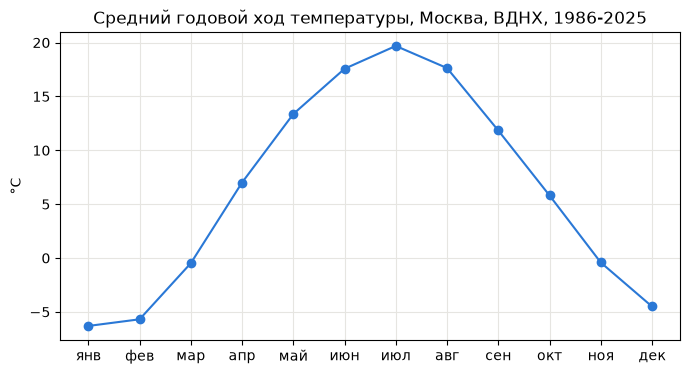

In [11]:
# Средний годовой ход: усредняем каждый месяц по всем годам ряда.
by_month = {}
for key in months:
    number = key[1]
    if number not in by_month:
        by_month[number] = []
    by_month[number].append(months[key])

numbers = sorted(by_month.keys())
values = []
for number in numbers:
    values.append(aisori.mean(by_month[number]))

# Подписи месяцев словами: по цифрам 1-12 читать неудобно.
short = ['янв', 'фев', 'мар', 'апр', 'май', 'июн',
         'июл', 'авг', 'сен', 'окт', 'ноя', 'дек']
labels = []
for number in numbers:
    labels.append(short[number - 1])

plt.figure(figsize=(8, 4))
plt.plot(numbers, values, color='#2a78d6', marker='o')
plt.xticks(numbers, labels)
plt.title(f'Средний годовой ход температуры, {STATION}, '
          f'{min(years)}-{max(years)}')
plt.ylabel('°C')
plt.grid(color='#e6e5e1')
plt.show()

## Шаг 5. Расшифровываем кодовые поля

Часть полей хранит код из таблиц Всемирной метеорологической
организации, а не саму величину. Например, видимость 95 означает
2 километра, а не 95.

In [12]:
print('код 25  ->', aisori.visibility_km(25), 'км')
print('код 95  ->', aisori.visibility_km(95), 'км')
print('код 52  ->', aisori.visibility_km(52), '(в таблице не используется)')
print()

visibility = aisori.decode_column(data['visibility_code'],
                                  aisori.visibility_km)
print('Видимость, первые 8 сроков:', visibility[:8])

код 25  -> 2.5 км
код 95  -> 2.0 км
код 52  -> None (в таблице не используется)

Видимость, первые 8 сроков: [10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0]


In [13]:
# Направление ветра: код 0 — штиль, код 999 — нет данных.
rose = aisori.wind_rose(data['wind_direction'])

print('Повторяемость направлений, доля:')
for name in aisori.COMPASS:
    print('   ', name, round(rose[name], 3))
print()
print('Доля штилей:',
      round(aisori.calm_share(data['wind_direction']) * 100, 1), '%')

Повторяемость направлений, доля:
    С 0.126
    СВ 0.073
    В 0.073
    ЮВ 0.135
    Ю 0.142
    ЮЗ 0.153
    З 0.159
    СЗ 0.138

Доля штилей: 23.9 %


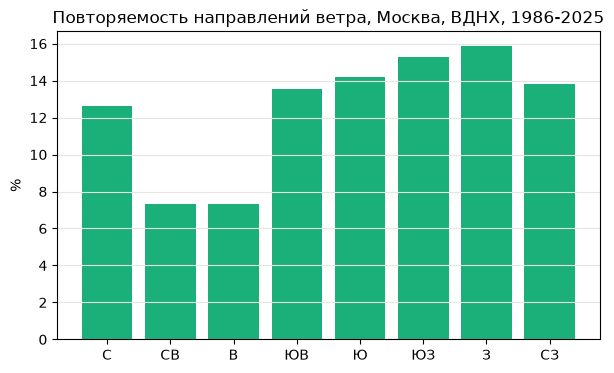

In [14]:
# Роза ветров столбиками.
heights = []
for name in aisori.COMPASS:
    heights.append(rose[name] * 100)

plt.figure(figsize=(7, 4))
plt.bar(aisori.COMPASS, heights, color='#1baf7a')
plt.title(f'Повторяемость направлений ветра, {STATION}, '
          f'{min(years)}-{max(years)}')
plt.ylabel('%')
plt.grid(axis='y', color='#e6e5e1')
plt.show()

## Шаг 6. Сохраняем результат в обычный CSV

Это главная задача модуля: превратить формат фиксированной ширины
в файл, который без настройки открывают Excel, QGIS.

In [15]:
aisori.save_csv(data, 'check.csv')
aisori.save_table(days, 'days.csv', 'дата', 'температура')

# Смотрим первые строки того, что получилось.
with open('days.csv', encoding='utf-8') as result_file:
    rows = result_file.readlines()

for number in range(5):
    print(rows[number].rstrip())

дата,температура
1986-1-1,-8.262500000000001
1986-1-2,-8.7375
1986-1-3,-11.537500000000001
1986-1-4,-10.899999999999999


## Шаг 7. Норма, аномалии и тренд

На фрагменте за один год тренд посчитать нельзя: нужен полный архив.
Ниже показано, как считается наклон, на маленьком примере.

In [16]:
# Пример: три года со средними 5.0, 6.0 и 7.0 градуса.
example = {2000: 5.0, 2010: 6.0, 2020: 7.0}
slope, intercept = aisori.trend(example)

print('Наклон тренда:', round(slope, 2), '°C за десятилетие')

Наклон тренда: 1.0 °C за десятилетие


### Тренд и аномалии

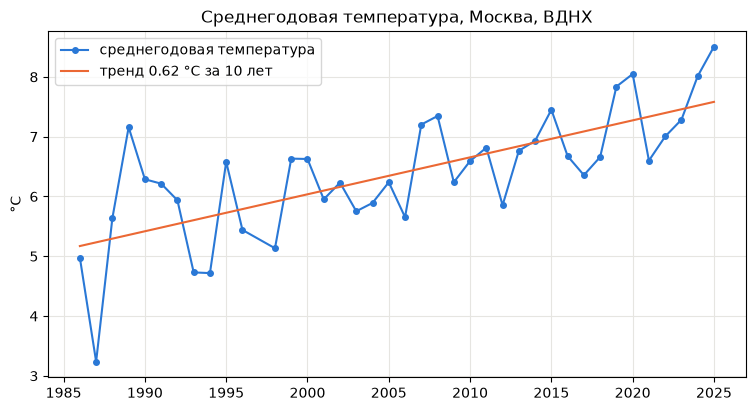

In [17]:
# Тренд считаем только если лет достаточно: по двум-трем точкам наклон не имеет смысла.
if len(years) >= 10:
    slope, intercept = aisori.trend(years)
    keys = sorted(years.keys())
    values = []
    line = []
    for year in keys:
        values.append(years[year])
        line.append(slope / 10 * year + intercept)

    plt.figure(figsize=(9, 4.5))
    plt.plot(keys, values, color='#2a78d6', marker='o', markersize=4,
             label='среднегодовая температура')
    plt.plot(keys, line, color='#eb6834',
             label='тренд ' + str(round(slope, 2)) + ' °C за 10 лет')
    plt.title('Среднегодовая температура, ' + STATION)
    plt.ylabel('°C')
    plt.grid(color='#e6e5e1')
    plt.legend()
    plt.show()
else:
    print('полных лет только', len(years))
    print('для графика по годам нужен полный архив')

Норма посчитана по годам 1991 - 2020 , всего 30


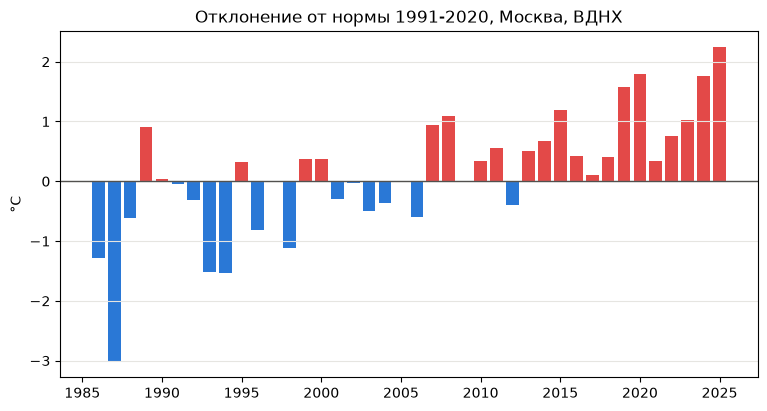

In [20]:
# Отклонения от климатической нормы: теплые годы красные, холодные синие. 
if len(years) >= 10:
    norm = aisori.norm_by_month(months)
    first, last, count = aisori.used_years(months)
    print('Норма посчитана по годам', first, '-', last, ', всего', count)

    anomaly = aisori.year_anomalies(years, norm)
    keys = sorted(anomaly.keys())
    values = []
    colors = []
    for key in keys:
        values.append(anomaly[key])
        if anomaly[key] >= 0:
            colors.append('#e34948')
        else:
            colors.append('#2a78d6')

    plt.figure(figsize=(9, 4.5))
    plt.bar(keys, values, color=colors)
    plt.axhline(0, color='#52514e', linewidth=1)
    plt.title(f'Отклонение от нормы 1991-2020, {STATION}')
    plt.ylabel('°C')
    plt.grid(axis='y', color='#e6e5e1')
    plt.show()
else:
    print('Для аномалий нужен ряд хотя бы в десять лет')

### Итог

На данных из репозитория - станция Москва, ВДНХ, 1986-2025 годы,
116 880 наблюдений - получается:

| Показатель | Значение |
|---|---|
| Тренд среднегодовой температуры | +0,62 °C за десятилетие |
| Самый теплый год | 2025 (8,51 °C) |
| Самый холодный год | 1987 (3,24 °C) |
| Доля штилей | 23,9 % |
| Преобладающее направление ветра | западное, 15,9 % |

Норму по месяцам считает функция `aisori.norm_by_month`,
отклонения от нее — функция `aisori.year_anomalies`.
Те же графики лежат в папке `docs/` и показаны в README.